In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Load the dataset
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv'
series = pd.read_csv(url, header=0, index_col=0, parse_dates=True)

# Display the first 5 rows of the dataset
print("Original Data:")
print(series.head())



Original Data:
            Temp
Date            
1981-01-01  20.7
1981-01-02  17.9
1981-01-03  18.8
1981-01-04  14.6
1981-01-05  15.8


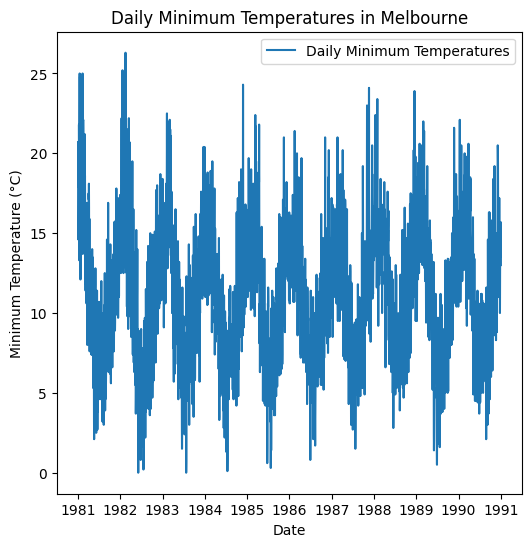

In [9]:
# Step 2: Plot the entire dataset
plt.figure(figsize=(6, 6))
plt.plot(series, label='Daily Minimum Temperatures')
plt.title('Daily Minimum Temperatures in Melbourne')
plt.xlabel('Date')
plt.ylabel('Minimum Temperature (°C)')
plt.legend()
plt.show()


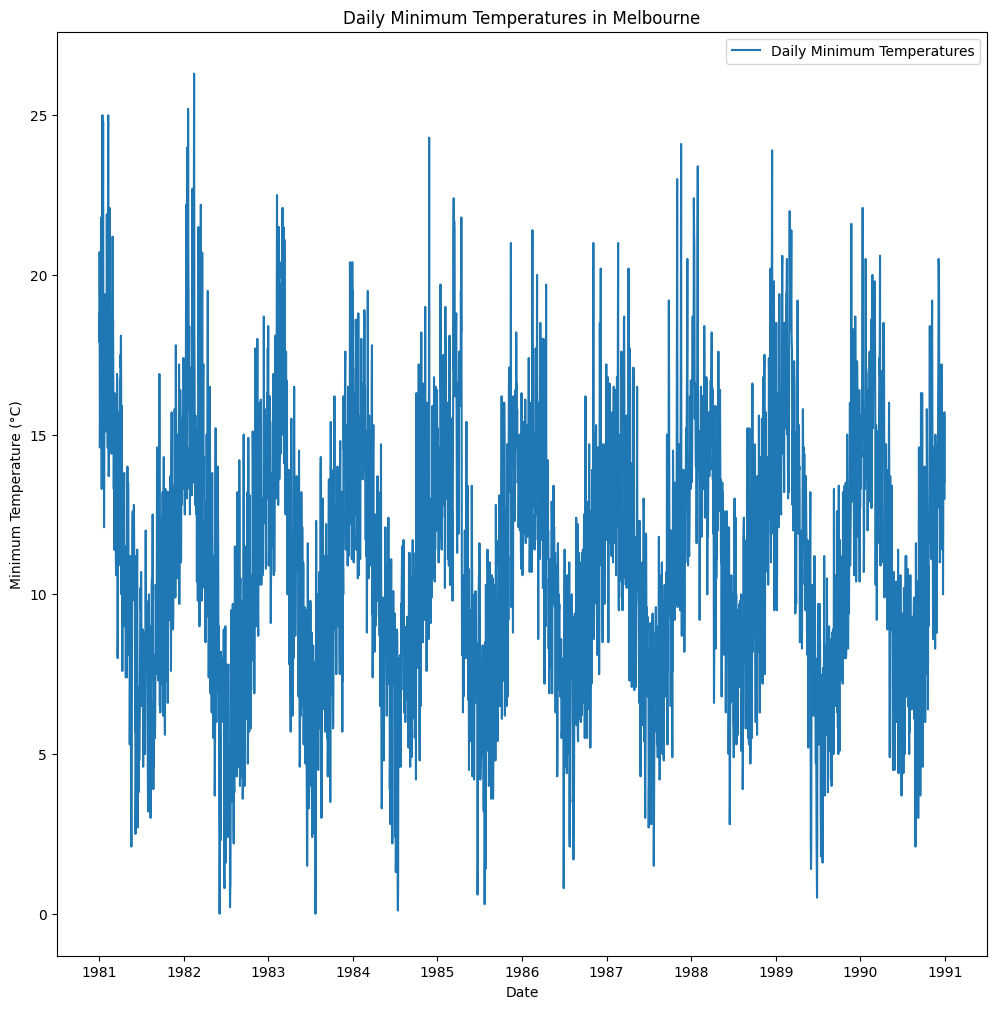

In [10]:
# Step 2: Plot the entire dataset
plt.figure(figsize=(12, 12))
plt.plot(series, label='Daily Minimum Temperatures')
plt.title('Daily Minimum Temperatures in Melbourne')
plt.xlabel('Date')
plt.ylabel('Minimum Temperature (°C)')
plt.legend()
plt.show()


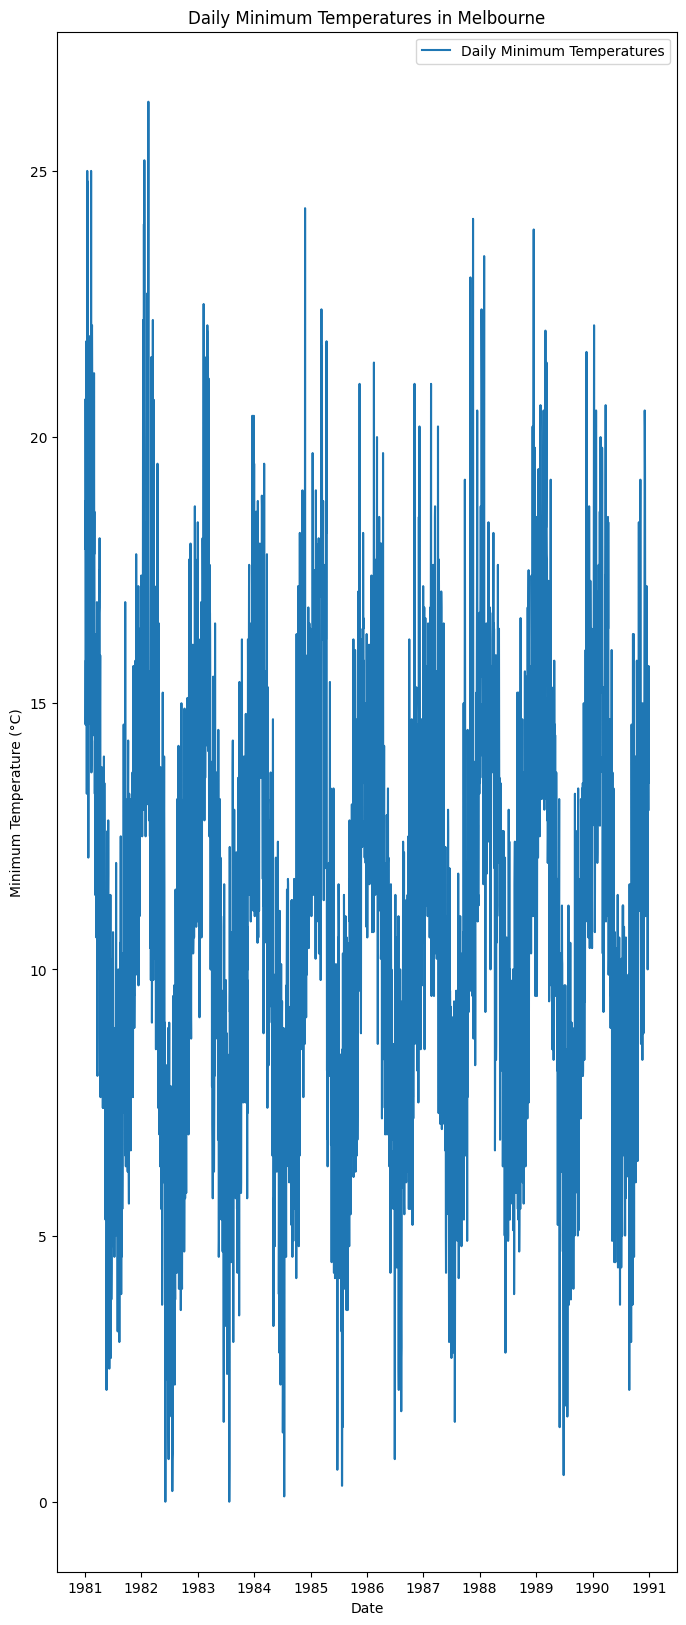

In [11]:
# Step 2: Plot the entire dataset
plt.figure(figsize=(8, 20))
plt.plot(series, label='Daily Minimum Temperatures')
plt.title('Daily Minimum Temperatures in Melbourne')
plt.xlabel('Date')
plt.ylabel('Minimum Temperature (°C)')
plt.legend()
plt.show()


In [5]:
# Step 3: Create Date Time Features
df = series.copy()
df['Month'] = df.index.month
df['Day'] = df.index.day

# Create additional date-time features
df['DayOfWeek'] = df.index.dayofweek
df['IsWeekend'] = (df['DayOfWeek'] >= 5).astype(int)
df['DayOfYear'] = df.index.dayofyear
df['IsHoliday'] = 0  # Assuming no public holidays, this can be modified
df['Season'] = (df['Month'] % 12 + 3) // 3  # Simplified Seasonal feature

# Display first 5 rows of DataFrame with Date Time Features
print("\nData with Date Time Features:")
print(df.head())


Data with Date Time Features:
            Temp  Month  Day  DayOfWeek  IsWeekend  DayOfYear  IsHoliday  \
Date                                                                       
1981-01-01  20.7      1    1          3          0          1          0   
1981-01-02  17.9      1    2          4          0          2          0   
1981-01-03  18.8      1    3          5          1          3          0   
1981-01-04  14.6      1    4          6          1          4          0   
1981-01-05  15.8      1    5          0          0          5          0   

            Season  
Date                
1981-01-01       1  
1981-01-02       1  
1981-01-03       1  
1981-01-04       1  
1981-01-05       1  


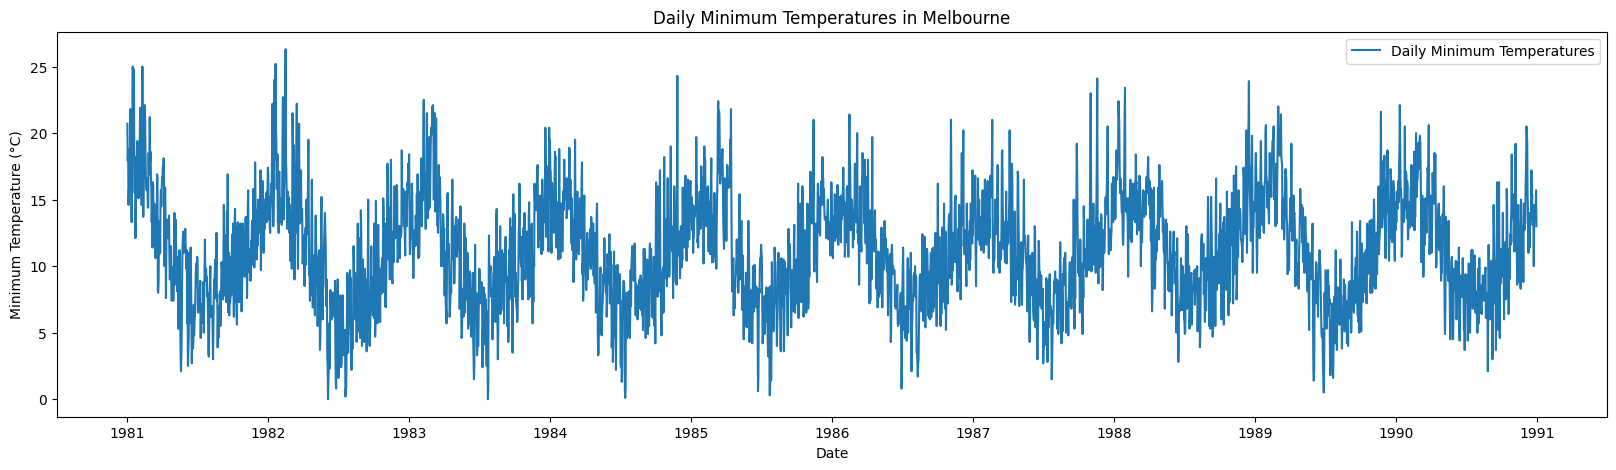

In [12]:
# Step 2: Plot the entire dataset
plt.figure(figsize=(20, 5))
plt.plot(series, label='Daily Minimum Temperatures')
plt.title('Daily Minimum Temperatures in Melbourne')
plt.xlabel('Date')
plt.ylabel('Minimum Temperature (°C)')
plt.legend()
plt.show()


In [6]:
# Step 4: Create Lag Features
# Lag for 3 time steps
df['t-3'] = df['Temp'].shift(3)
df['t-2'] = df['Temp'].shift(2)
df['t-1'] = df['Temp'].shift(1)

# Clean the DataFrame by dropping NaN values
lagged_df = df.dropna().copy()

# Display first 5 rows of DataFrame with Lag Features
print("\nData with Lag Features:")
print(lagged_df[['t-3', 't-2', 't-1', 'Temp']].head())



Data with Lag Features:
             t-3   t-2   t-1  Temp
Date                              
1981-01-04  20.7  17.9  18.8  14.6
1981-01-05  17.9  18.8  14.6  15.8
1981-01-06  18.8  14.6  15.8  15.8
1981-01-07  14.6  15.8  15.8  15.8
1981-01-08  15.8  15.8  15.8  17.4


In [7]:
# Step 5: Create Rolling Window Statistics
rolling_window_width = 3
df['RollingMean'] = df['Temp'].shift(1).rolling(window=rolling_window_width).mean()
df['RollingMin'] = df['Temp'].shift(1).rolling(window=rolling_window_width).min()
df['RollingMax'] = df['Temp'].shift(1).rolling(window=rolling_window_width).max()

# Display first 5 rows with Rolling Statistics
print("\nData with Rolling Window Statistics:")
print(df[['RollingMean', 'RollingMin', 'RollingMax', 'Temp']].head(5))



Data with Rolling Window Statistics:
            RollingMean  RollingMin  RollingMax  Temp
Date                                                 
1981-01-01          NaN         NaN         NaN  20.7
1981-01-02          NaN         NaN         NaN  17.9
1981-01-03          NaN         NaN         NaN  18.8
1981-01-04    19.133333        17.9        20.7  14.6
1981-01-05    17.100000        14.6        18.8  15.8


In [8]:
# Step 6: Create Expanding Window Statistics
df['ExpandingMean'] = df['Temp'].shift(1).expanding().mean()
df['ExpandingMin'] = df['Temp'].shift(1).expanding().min()
df['ExpandingMax'] = df['Temp'].shift(1).expanding().max()

# Display first 5 rows with Expanding Statistics
print("\nData with Expanding Window Statistics:")
print(df[['ExpandingMean', 'ExpandingMin', 'ExpandingMax', 'Temp']].head(5))


Data with Expanding Window Statistics:
            ExpandingMean  ExpandingMin  ExpandingMax  Temp
Date                                                       
1981-01-01            NaN           NaN           NaN  20.7
1981-01-02      20.700000          20.7          20.7  17.9
1981-01-03      19.300000          17.9          20.7  18.8
1981-01-04      19.133333          17.9          20.7  14.6
1981-01-05      18.000000          14.6          20.7  15.8
